# Treasury Market-Basket Analysis — 02: Statistical Significance & Power

**Purpose.** The sibling notebooks in this directory compute association-rule
metrics (support, confidence, lift) on the treasury service basket matrix. This
notebook asks the question that decides whether any of those numbers mean
anything: **is any co-occurrence pattern statistically distinguishable from
chance at this sample size?**

The answer, established below, is **no** — and the useful contribution of this
notebook is to quantify *how much data would be required* before it could be
yes. That number is the actionable output.

## Data source

| Item | Value |
|---|---|
| Fact table | `PL_DATA_STUDIO.DERIVED.CORE_TREASURY_ACCOUNTS_MONTHLY` |
| Dimension (group names) | `PL_DATA_STUDIO.INTEGRATION_TESTING."TreasuryServices_Prod_7-1-26"` |
| `VERSION_PARTITION` | `2.5` (pinned) |
| `DATE_PARTITION` | `2026-08-31` (pinned) |
| Baskets (`RELATIONSHIP_ID`) | **9** |
| Items (`TREASURY_SERVICE_NAME`) | **11** |

Both partition columns are pinned; an unpinned query silently mixes version
`2.3` and `2.5`. Loading and the fan-out-safe dimension join are delegated to
`mba_common.load_snapshot`, which pre-deduplicates the dimension (a naive join
doubles the fact rows).

## The degeneracy warning, up front

Per `GROUND_TRUTH.md`, which is authoritative and is not re-derived here:

- At the **service-group** grain there are 3 groups and all 3 appear in all 9
  baskets. Every support, confidence and lift is a constant. There is nothing
  to test.
- At the **service-name** grain there is exactly one bit of variation: 9 of the
  11 services appear in all 9 baskets; `Incoming Foreign` and `Outgoing Foreign`
  appear in 8, both absent from the same single basket.
- Consequently **lift takes only two values in the entire dataset: 1.0 and
  1.125**. Support is quantised to ninths.

This notebook therefore operates at the service-name grain, where at least one
non-degenerate contingency table exists, and treats the result as a methodology
demonstration rather than a business finding.

## The statistical machinery

| Tool | What it does here | Why this choice |
|---|---|---|
| **Fisher's exact test** | Exact null probability of the observed 2×2 co-occurrence table, conditioning on both margins. | Exact for *any* n. The only defensible choice at n=9. |
| **Pearson χ² (Yates)** | Reported *only* as a contrast. | Asymptotic. Needs expected cell counts ≳5; here they fall near 0.1. Its p-values are not valid; they are shown to demonstrate the disagreement, not to be used. |
| **Benjamini–Hochberg FDR** | Controls the expected proportion of false discoveries across the family of 55 pair tests. | 55 simultaneous tests at α=0.05 would be expected to yield ≈2.75 spurious "findings" by construction. Implemented directly in numpy. |
| **Power** | P(reject H₀ given a specified true association) — the chance the test *would* find a real effect of a given size. | Converts "we found nothing" into the quantified "we could not have found anything". |
| **Required sample size** | Smallest basket count n giving 80% power at a specified true lift. | The single most actionable number in this deliverable. |
| **Minimum detectable effect (MDE)** | Smallest true lift detectable with 80% power at fixed n. | The same limit expressed from the other direction. |
| **Wilson / Clopper–Pearson CI** | Interval estimate for each item's support. | The normal-approximation (Wald) interval is invalid at n=9 and degenerates to zero width at support = 1.0; these two do not. |

All tests are **two-sided**. A one-sided test aimed at positive association
would have marginally more power; two-sided is used throughout so that the pair
tests and the power calculations answer exactly the same question.

In [1]:
# --- import bootstrap: works locally and inside a Snowflake notebook ---
import sys
from pathlib import Path

try:
    import mba_common
except ModuleNotFoundError:
    _candidates = [
        Path.cwd(),
        Path.cwd() / "investigations" / "treasury_mba",
        Path("/home/udf/notebook"),      # Snowflake Notebooks working dir
        Path("/tmp/notebook"),
        Path("/usr/share/notebook"),
    ]
    for _p in _candidates:
        if (_p / "mba_common.py").is_file() and str(_p) not in sys.path:
            sys.path.insert(0, str(_p))
    try:
        import mba_common
    except ModuleNotFoundError as exc:
        raise ModuleNotFoundError(
            "mba_common.py was not found on sys.path. It must be uploaded "
            "alongside this notebook (same stage / same directory). Searched: "
            + ", ".join(str(p) for p in _candidates)
        ) from exc

print(f"mba_common loaded from {mba_common.__file__}")

mba_common loaded from /Users/jeisenman/ra/qtwo_bench/investigations/treasury_mba/mba_common.py


In [2]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy import stats

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# seaborn is installed but broken in this environment (matplotlib 3.10 removed
# matplotlib.cm.register_cmap). matplotlib only -- see GROUND_TRUTH.md.
print(f"numpy {np.__version__} | pandas {pd.__version__} | scipy {scipy.__version__}")

numpy 1.26.1 | pandas 2.3.3 | scipy 1.16.2


## Parameters

Everything tunable lives in this one cell.

In [3]:
# ============================= PARAMETERS =============================
VERSION_PARTITION = "2.5"                     # pinned fact-table version
DATE_PARTITION    = "2026-08-31"              # pinned snapshot date
ITEM_GRAIN        = mba_common.ITEM_SERVICE   # ITEM_SERVICE | ITEM_GROUP

ALPHA        = 0.05          # per-test two-sided significance level
FDR_Q        = 0.05          # Benjamini-Hochberg target false-discovery rate
TARGET_POWER = 0.80          # power used for sample-size / MDE calculations

# Fisher's exact has no closed-form power function; power is simulated, with
# caching on the 2x2 table so repeated draws are cheap.
POWER_REPS  = 3000           # replicates for grid / scan evaluations
REFINE_REPS = 8000           # replicates for bisection and headline numbers
RNG_SEED    = 20260831

LIFT_GRID      = [1.05, 1.1, 1.15, 1.25, 1.4, 1.5, 1.75, 2.0]
HEADLINE_LIFTS = [1.1, 1.25, 1.5, 2.0]
MDE_N          = [9, 100, 1000, 2073]

# Marginal supports assumed by the power model (see section 5).
BALANCED_MARGIN = 0.5        # most-favourable / maximum-information case
OBSERVED_MARGIN = 8 / 9      # the actual Incoming/Outgoing Foreign margin
# ======================================================================

## 1. Load the snapshot and confirm the degeneracy

`mba_common.load_snapshot` is used as-is; no loader logic is reimplemented here.

In [4]:
snap = mba_common.load_snapshot(
    version_partition=VERSION_PARTITION,
    date_partition=DATE_PARTITION,
)
matrix = snap.basket_matrix(ITEM_GRAIN)
N_BASKETS = snap.n_baskets

print(f"snapshot {snap.version_partition} / {snap.date_partition}")
print(f"rows={len(snap.rows)}  baskets={N_BASKETS}  items={matrix.shape[1]}")
matrix.astype(int)

snapshot 2.5 / 2026-08-31
rows=97  baskets=9  items=11


TREASURY_SERVICE_NAME,Checks Deposited,Debits,Incoming Domestic,Incoming Foreign,Items Deposited,Monthly Servicing,Outgoing Domestic,Outgoing Foreign,Retail Item,Wholesale Deposit,Wholesale Item
RELATIONSHIP_ID,,,,,,,,,,,
025d8b3e-d123-42a7-9a04-2e604484193c,1,1,1,0,1,1,1,0,1,1,1
257bd20b-c38f-4726-87ce-a4cc9ed0df58,1,1,1,1,1,1,1,1,1,1,1
38550f29-8fca-49f4-be49-56e0a7e7e8e0,1,1,1,1,1,1,1,1,1,1,1
47102bd7-e025-4f4c-9634-d5de8c27ee25,1,1,1,1,1,1,1,1,1,1,1
5cc9db33-b27c-48a8-b7d0-d69aa632f092,1,1,1,1,1,1,1,1,1,1,1
7638e194-7916-4fae-879c-22a95fbccc57,1,1,1,1,1,1,1,1,1,1,1
901ba45b-5481-4a03-86b8-67f961665011,1,1,1,1,1,1,1,1,1,1,1
9858122e-0494-4b9a-b5bf-45eea25773b2,1,1,1,1,1,1,1,1,1,1,1
e53e199b-ef9b-4bc6-b709-452bb6b52514,1,1,1,1,1,1,1,1,1,1,1


In [5]:
report = mba_common.degeneracy_report(matrix)
for key, value in report.items():
    print(f"{key:>22} : {value}")

print()
if report["is_degenerate"]:
    print("DEGENERATE: fewer than two distinct lift values exist. No approach, "
          "statistical or otherwise, can surface differential structure here.")
else:
    print(f"Only {len(report['distinct_lift_values'])} distinct lift value(s) are "
          f"attainable anywhere in this dataset: {report['distinct_lift_values']}")
    print(f"{len(report['universal_items'])} of {matrix.shape[1]} items appear in "
          f"every basket, so their rows/columns carry zero information.")

             n_baskets : 9
               n_items : 11
      distinct_baskets : 2
       universal_items : ['Checks Deposited', 'Debits', 'Incoming Domestic', 'Items Deposited', 'Monthly Servicing', 'Outgoing Domestic', 'Retail Item', 'Wholesale Deposit', 'Wholesale Item']
  distinct_lift_values : [1.0, 1.125]
         is_degenerate : False
               verdict : near-degenerate: only 2 distinct basket signatures, so any 'pattern' restates a single deviating basket

Only 2 distinct lift value(s) are attainable anywhere in this dataset: [1.0, 1.125]
9 of 11 items appear in every basket, so their rows/columns carry zero information.


In [6]:
support = mba_common.item_support(matrix)
basket_sizes = matrix.sum(axis=1).sort_values()

print(f"Item support, quantised to 1/{N_BASKETS} = "
      f"{mba_common.min_detectable_support_delta(N_BASKETS):.4f}:")
display(
    support.to_frame("support").assign(
        baskets=(support * N_BASKETS).round().astype(int)
    )
)
print("Basket sizes (number of services per relationship):")
display(basket_sizes.to_frame("n_items"))

Item support, quantised to 1/9 = 0.1111:


,support,baskets
TREASURY_SERVICE_NAME,,
Checks Deposited,1.000000,9
Debits,1.000000,9
Incoming Domestic,1.000000,9
Items Deposited,1.000000,9
Monthly Servicing,1.000000,9
Outgoing Domestic,1.000000,9
Retail Item,1.000000,9
Wholesale Deposit,1.000000,9
Wholesale Item,1.000000,9


Basket sizes (number of services per relationship):


,n_items
RELATIONSHIP_ID,
025d8b3e-d123-42a7-9a04-2e604484193c,9
257bd20b-c38f-4726-87ce-a4cc9ed0df58,11
38550f29-8fca-49f4-be49-56e0a7e7e8e0,11
47102bd7-e025-4f4c-9634-d5de8c27ee25,11
5cc9db33-b27c-48a8-b7d0-d69aa632f092,11
7638e194-7916-4fae-879c-22a95fbccc57,11
901ba45b-5481-4a03-86b8-67f961665011,11
9858122e-0494-4b9a-b5bf-45eea25773b2,11
e53e199b-ef9b-4bc6-b709-452bb6b52514,11


## 2. Per-pair exact inference

For every unordered pair of services (A, B) we build the 2×2 table

|            | B present | B absent |
|---|---|---|
| **A present** | a | b |
| **A absent**  | c | d |

and test H₀: A and B are independent.

Two structural facts about these tables matter:

1. When either item is **universal** (present in all 9 baskets) one margin is
   zero. The table is then fully determined by its margins, only one table is
   consistent with the null, and Fisher's exact test returns p = 1.0 by
   construction. That is not weak evidence — it is the formal statement that a
   constant variable cannot be associated with anything.
2. The only pair with a non-trivial table is
   `Incoming Foreign` × `Outgoing Foreign`, which co-occur **perfectly**
   (a=8, b=0, c=0, d=1). Its exact p-value is derived in section 3.

χ² is computed alongside purely for contrast, and returned as `NaN` where a
margin is zero rather than being papered over.

In [7]:
def contingency(matrix: pd.DataFrame, item_a: str, item_b: str) -> np.ndarray:
    """Return the 2x2 table [[both, a_only], [b_only, neither]] for a pair.

    Args:
        matrix: Boolean basket x item incidence matrix.
        item_a: Column name of the first item.
        item_b: Column name of the second item.

    Returns:
        A 2x2 integer array of counts.
    """
    if item_a not in matrix.columns or item_b not in matrix.columns:
        raise KeyError(f"unknown item(s): {item_a!r}, {item_b!r}")
    a = matrix[item_a].to_numpy(dtype=bool)
    b = matrix[item_b].to_numpy(dtype=bool)
    return np.array(
        [
            [int(np.count_nonzero(a & b)), int(np.count_nonzero(a & ~b))],
            [int(np.count_nonzero(~a & b)), int(np.count_nonzero(~a & ~b))],
        ],
        dtype=int,
    )


def has_zero_margin(table: np.ndarray) -> bool:
    """True when any row or column margin is zero (table is determined)."""
    return bool((table.sum(axis=0) == 0).any() or (table.sum(axis=1) == 0).any())


def chi2_yates(table: np.ndarray) -> float:
    """Pearson chi-square p-value with Yates correction; NaN if undefined."""
    if has_zero_margin(table):
        return float("nan")
    try:
        return float(stats.chi2_contingency(table, correction=True)[1])
    except ValueError:
        return float("nan")


def min_expected(table: np.ndarray) -> float:
    """Smallest expected cell count under independence."""
    n = int(table.sum())
    if n == 0:
        raise ValueError("empty contingency table")
    expected = np.outer(table.sum(axis=1), table.sum(axis=0)) / n
    return float(expected.min())

In [8]:
pairs = mba_common.pair_metrics(matrix)

records = []
for row in pairs.itertuples(index=False):
    table = contingency(matrix, row.antecedent, row.consequent)
    odds, p_fisher = stats.fisher_exact(table, alternative="two-sided")
    records.append(
        {
            "pair": f"{row.antecedent} x {row.consequent}",
            "a_both": table[0, 0], "b_a_only": table[0, 1],
            "c_b_only": table[1, 0], "d_neither": table[1, 1],
            "support": row.support,
            "lift": row.lift,
            "jaccard": row.jaccard,
            "odds_ratio": odds,
            "p_fisher": float(p_fisher),
            "p_chi2_yates": chi2_yates(table),
            "min_expected_cell": min_expected(table),
            "zero_margin": has_zero_margin(table),
        }
    )

tests = pd.DataFrame(records).sort_values("p_fisher", ignore_index=True)

print(f"{len(tests)} unordered pairs tested = C({matrix.shape[1]}, 2) = "
      f"{math.comb(matrix.shape[1], 2)}")
print(f"pairs with a zero margin (p = 1.0 by construction): "
      f"{int(tests['zero_margin'].sum())}")
print(f"pairs with a genuinely testable table               : "
      f"{int((~tests['zero_margin']).sum())}")
print(f"smallest expected cell count anywhere: "
      f"{tests['min_expected_cell'].min():.3f}  (chi-square needs >= ~5)")
tests.head(12)

55 unordered pairs tested = C(11, 2) = 55
pairs with a zero margin (p = 1.0 by construction): 54
pairs with a genuinely testable table               : 1
smallest expected cell count anywhere: 0.000  (chi-square needs >= ~5)


,pair,a_both,b_a_only,c_b_only,d_neither,support,lift,jaccard,odds_ratio,p_fisher,p_chi2_yates,min_expected_cell,zero_margin
0,Incoming Foreign x Outgoing Foreign,8,0,0,1,0.888889,1.125,1.000000,inf,0.111111,0.189351,0.111111,False
1,Monthly Servicing x Wholesale Deposit,9,0,0,0,1.000000,1.000,1.000000,NaN,1.000000,NaN,0.000000,True
2,Monthly Servicing x Wholesale Item,9,0,0,0,1.000000,1.000,1.000000,NaN,1.000000,NaN,0.000000,True
3,Outgoing Domestic x Retail Item,9,0,0,0,1.000000,1.000,1.000000,NaN,1.000000,NaN,0.000000,True
4,Outgoing Domestic x Wholesale Deposit,9,0,0,0,1.000000,1.000,1.000000,NaN,1.000000,NaN,0.000000,True
5,Outgoing Domestic x Wholesale Item,9,0,0,0,1.000000,1.000,1.000000,NaN,1.000000,NaN,0.000000,True
6,Retail Item x Wholesale Deposit,9,0,0,0,1.000000,1.000,1.000000,NaN,1.000000,NaN,0.000000,True
7,Retail Item x Wholesale Item,9,0,0,0,1.000000,1.000,1.000000,NaN,1.000000,NaN,0.000000,True
8,Wholesale Deposit x Wholesale Item,9,0,0,0,1.000000,1.000,1.000000,NaN,1.000000,NaN,0.000000,True
9,Checks Deposited x Incoming Foreign,8,1,0,0,0.888889,1.000,0.888889,NaN,1.000000,NaN,0.000000,True


In [9]:
cmp = tests[["pair", "p_fisher", "p_chi2_yates", "min_expected_cell"]]
disagree = cmp[
    cmp["p_chi2_yates"].notna()
    & (np.abs(cmp["p_fisher"] - cmp["p_chi2_yates"]) > 1e-9)
]
print("Pairs where Fisher's exact and Yates-corrected chi-square disagree:")
display(disagree)
print(
    "Each chi-square p-value above comes from a table whose smallest expected\n"
    "cell count is far below 5, so the chi-square distribution is not a valid\n"
    "reference distribution. These values are shown for contrast and are NOT\n"
    "used for any inference in this notebook."
)

Pairs where Fisher's exact and Yates-corrected chi-square disagree:


,pair,p_fisher,p_chi2_yates,min_expected_cell
0,Incoming Foreign x Outgoing Foreign,0.111111,0.189351,0.111111


Each chi-square p-value above comes from a table whose smallest expected
cell count is far below 5, so the chi-square distribution is not a valid
reference distribution. These values are shown for contrast and are NOT
used for any inference in this notebook.


## 3. The perfect-co-occurrence pair, worked by hand

`Incoming Foreign` and `Outgoing Foreign` co-occur in 8 of 8 opportunities
(Jaccard = 1.0). The table is

|            | OF present | OF absent |
|---|---|---|
| **IF present** | 8 | 0 |
| **IF absent**  | 0 | 1 |

Fisher's exact test conditions on the margins (8, 1) and (8, 1). Only **two**
tables are consistent with those margins — the observed one and the one with
a = 7 — and the hypergeometric probability of the observed table is

$$P = \frac{\binom{8}{8}\binom{1}{0}}{\binom{9}{8}} = \frac{1}{9} = 0.1111$$

So the smallest p-value this table can produce — the p-value of *perfect*
association — is **0.111**. It cannot be smaller. **At n = 9, perfect
co-occurrence is not statistically significant at α = 0.05**, and no choice of
algorithm, metric, or test changes that. This is the cleanest available
demonstration that the binding constraint is data volume, not analysis.

In [10]:
PERFECT = ("Incoming Foreign", "Outgoing Foreign")
if all(item in matrix.columns for item in PERFECT):
    t = contingency(matrix, *PERFECT)
    _, p_perfect = stats.fisher_exact(t, alternative="two-sided")
    analytic = 1.0 / math.comb(N_BASKETS, int(t[0, 0]))
    print(f"contingency table            : {t.tolist()}")
    print(f"Fisher's exact two-sided p   : {p_perfect:.6f}")
    print(f"hand-derived 1/C({N_BASKETS},{t[0, 0]})        : {analytic:.6f}")
    print(f"Jaccard                      : 1.0 (perfect co-occurrence)")
    print(f"significant at alpha={ALPHA}?    : {bool(p_perfect < ALPHA)}")
    print()
    print(f"The smallest p-value attainable from ANY table with these margins "
          f"at n={N_BASKETS}\nis {p_perfect:.4f}, which exceeds alpha={ALPHA}. "
          f"Perfect association is undetectable here.")
else:
    print(f"{PERFECT} not present at grain {ITEM_GRAIN}; skipping.")

contingency table            : [[8, 0], [0, 1]]
Fisher's exact two-sided p   : 0.111111
hand-derived 1/C(9,8)        : 0.111111
Jaccard                      : 1.0 (perfect co-occurrence)
significant at alpha=0.05?    : False

The smallest p-value attainable from ANY table with these margins at n=9
is 0.1111, which exceeds alpha=0.05. Perfect association is undetectable here.


## 4. Benjamini–Hochberg FDR across the pair family

We ran 55 tests. Under a true global null, α = 0.05 would be *expected* to throw
up about 2.75 "significant" pairs by chance alone. Any pair-mining exercise that
reports uncorrected p-values is therefore manufacturing findings.

Benjamini–Hochberg: sort the m p-values ascending, find the largest rank k with
$p_{(k)} \le \frac{k}{m} q$, and reject every hypothesis up to that rank.
Implemented directly below.

In [11]:
def benjamini_hochberg(p_values, q: float = 0.05):
    """Benjamini-Hochberg step-up procedure for FDR control.

    Args:
        p_values: Array-like of p-values. NaN is treated as 1.0 (no evidence).
        q: Target false-discovery rate.

    Returns:
        Tuple ``(reject, adjusted, threshold)`` where ``reject`` is a boolean
        mask in input order, ``adjusted`` holds BH-adjusted p-values, and
        ``threshold`` is the largest p(k) satisfying p(k) <= k/m * q, or 0.0
        when nothing is rejected.

    Raises:
        ValueError: If no p-values are supplied.
    """
    p = np.asarray(p_values, dtype=float)
    p = np.where(np.isnan(p), 1.0, p)
    m = p.size
    if m == 0:
        raise ValueError("no p-values supplied")
    order = np.argsort(p, kind="stable")
    ranked = p[order]
    k = np.arange(1, m + 1)
    passes = ranked <= (k / m) * q
    if passes.any():
        k_max = int(k[passes].max())
        threshold = float(ranked[k_max - 1])
    else:
        k_max, threshold = 0, 0.0
    # Monotone step-up adjusted p-values.
    adjusted_sorted = np.clip(
        np.minimum.accumulate((ranked * m / k)[::-1])[::-1], 0.0, 1.0
    )
    adjusted = np.empty(m, dtype=float)
    adjusted[order] = adjusted_sorted
    reject = np.zeros(m, dtype=bool)
    if k_max:
        reject[order[:k_max]] = True
    return reject, adjusted, threshold

In [12]:
reject, p_adj, bh_threshold = benjamini_hochberg(tests["p_fisher"], q=FDR_Q)
tests["p_fisher_bh"] = p_adj
tests["significant_bh"] = reject

m = len(tests)
n_raw = int((tests["p_fisher"] < ALPHA).sum())
n_bh = int(reject.sum())

print(f"tests in the family (m)                      : {m}")
print(f"false positives expected at alpha={ALPHA}        : {m * ALPHA:.2f}")
print(f"pairs with raw p < {ALPHA}                       : {n_raw}")
print(f"pairs surviving BH at q={FDR_Q}                  : {n_bh}")
print(f"BH critical threshold                        : {bh_threshold:.6f}")
print(f"smallest p-value observed                    : "
      f"{tests['p_fisher'].min():.6f}")
print(f"smallest BH-adjusted p-value                 : "
      f"{tests['p_fisher_bh'].min():.6f}")
print()
assert n_bh == 0, "unexpected: a pair survived FDR correction"
print("RESULT: no service pair is significantly associated. Not one.")
print("The smallest attainable p-value in this dataset already exceeds alpha")
print("before any multiplicity correction is applied; BH only reinforces it.")

tests in the family (m)                      : 55
false positives expected at alpha=0.05        : 2.75
pairs with raw p < 0.05                       : 0
pairs surviving BH at q=0.05                  : 0
BH critical threshold                        : 0.000000
smallest p-value observed                    : 0.111111
smallest BH-adjusted p-value                 : 1.000000

RESULT: no service pair is significantly associated. Not one.
The smallest attainable p-value in this dataset already exceeds alpha
before any multiplicity correction is applied; BH only reinforces it.


## 5. Power: what *could* we have detected?

Fisher's exact test has no closed-form power function, so power is obtained by
simulation: draw the four cell counts from a multinomial with the cell
probabilities implied by a chosen pair of marginal supports and a chosen true
lift, run the exact test, and record the rejection rate. Results are cached on
the 2×2 table, which makes this inexpensive at small n.

Two marginal regimes are reported, because the choice matters enormously:

- **Balanced, p_A = p_B = 0.5.** Each basket is maximally informative. This is
  the *best case* — the regime in which a 2×2 test has the most power for a
  given n — so the sample sizes quoted are **lower bounds**.
- **Observed, p_A = p_B = 8/9 = 0.889.** The actual marginals of the only
  informative pair in this data. Supports this close to 1.0 cap the maximum
  attainable lift at 1/0.889 = 1.125 and leave almost no variance to test.

The balanced-regime numbers are the honest headline, on the assumption that a
larger basket population would also bring more varied adoption marginals.

In [13]:
def max_feasible_lift(p_a: float, p_b: float) -> float:
    """Largest lift attainable at these marginals (perfect co-occurrence)."""
    if not (0.0 < p_a <= 1.0 and 0.0 < p_b <= 1.0):
        raise ValueError("marginal supports must lie in (0, 1]")
    return min(p_a, p_b) / (p_a * p_b)


def cell_probabilities(p_a: float, p_b: float, lift: float) -> np.ndarray:
    """Cell probabilities [both, a_only, b_only, neither] for a true lift.

    Args:
        p_a: True marginal support of item A.
        p_b: True marginal support of item B.
        lift: True lift; 1.0 is independence.

    Returns:
        Length-4 probability vector summing to 1.

    Raises:
        ValueError: If the lift is infeasible at these marginals.
    """
    p_ab = lift * p_a * p_b
    probs = np.array(
        [p_ab, p_a - p_ab, p_b - p_ab, 1.0 - p_a - p_b + p_ab], dtype=float
    )
    if probs.min() < -1e-12:
        raise ValueError(
            f"lift={lift} is infeasible at marginals ({p_a:.4f}, {p_b:.4f}); "
            f"max feasible lift = {max_feasible_lift(p_a, p_b):.4f}"
        )
    probs = np.clip(probs, 0.0, None)
    return probs / probs.sum()


_FISHER_CACHE: dict = {}


def _fisher_p(cells) -> float:
    """Two-sided Fisher p-value for a flat 4-vector of cell counts, cached."""
    key = (int(cells[0]), int(cells[1]), int(cells[2]), int(cells[3]))
    hit = _FISHER_CACHE.get(key)
    if hit is None:
        hit = float(
            stats.fisher_exact(
                [[key[0], key[1]], [key[2], key[3]]], alternative="two-sided"
            )[1]
        )
        _FISHER_CACHE[key] = hit
    return hit


def simulate_power(n: int, lift: float, p_a: float = 0.5, p_b: float = 0.5,
                   alpha: float = 0.05, reps: int = 3000, rng=None) -> float:
    """Monte-Carlo power of Fisher's exact test for a 2x2 association.

    Args:
        n: Number of baskets.
        lift: True lift under the alternative; 1.0 gives the type-I error rate.
        p_a: True marginal support of item A.
        p_b: True marginal support of item B.
        alpha: Two-sided significance level.
        reps: Simulation replicates.
        rng: Optional numpy Generator, for reproducibility.

    Returns:
        Estimated probability of rejecting H0.

    Raises:
        ValueError: If ``n`` < 2 or ``reps`` < 1.
    """
    if n < 2:
        raise ValueError("n must be >= 2")
    if reps < 1:
        raise ValueError("reps must be >= 1")
    rng = rng if rng is not None else np.random.default_rng(RNG_SEED)
    probs = cell_probabilities(p_a, p_b, lift)
    draws = rng.multinomial(n, probs, size=reps)
    hits = sum(1 for row in draws if _fisher_p(row) < alpha)
    return hits / reps

In [14]:
# Sanity check: at lift = 1.0 the rejection rate is the type-I error rate and
# must not exceed alpha. Fisher's exact is conservative on discrete data, so a
# value well below alpha is expected and correct.
for n_check in (9, 50, 500):
    t1 = simulate_power(n_check, 1.0, BALANCED_MARGIN, BALANCED_MARGIN, ALPHA,
                        reps=POWER_REPS, rng=np.random.default_rng(1))
    print(f"n={n_check:>4}  type-I error at lift=1.0: {t1:.4f}   "
          f"(nominal alpha={ALPHA}; Fisher is conservative)")

n=   9  type-I error at lift=1.0: 0.0323   (nominal alpha=0.05; Fisher is conservative)


n=  50  type-I error at lift=1.0: 0.0377   (nominal alpha=0.05; Fisher is conservative)


n= 500  type-I error at lift=1.0: 0.0443   (nominal alpha=0.05; Fisher is conservative)


In [15]:
def required_n(lift: float, p_a: float, p_b: float, target_power: float,
               alpha: float, rng, n_cap: int = 200_000) -> float:
    """Smallest basket count reaching ``target_power``, by scan then bisection.

    Args:
        lift: True lift to be detected.
        p_a: True marginal support of item A.
        p_b: True marginal support of item B.
        target_power: Power to achieve, e.g. 0.80.
        alpha: Two-sided significance level.
        rng: numpy Generator.
        n_cap: Largest n considered.

    Returns:
        The required number of baskets, or ``inf`` if ``n_cap`` is insufficient.
    """
    ladder = [9, 15, 25, 40, 60, 100, 160, 250, 400, 650, 1000,
              1600, 2500, 4000, 6500, 10_000, 20_000, 50_000, n_cap]
    lo, hi = None, None
    for n in ladder:
        if simulate_power(n, lift, p_a, p_b, alpha,
                          reps=POWER_REPS, rng=rng) >= target_power:
            hi = n
            break
        lo = n
    if hi is None:
        return float("inf")
    lo = lo if lo is not None else 2
    while hi - lo > max(2, int(0.02 * hi)):          # ~2% relative precision
        mid = (lo + hi) // 2
        if simulate_power(mid, lift, p_a, p_b, alpha,
                          reps=REFINE_REPS, rng=rng) >= target_power:
            hi = mid
        else:
            lo = mid
    return float(hi)

In [16]:
POWER_COL = f"n_for_{int(TARGET_POWER * 100)}pct_power"

rows = []
for label, margin in (("balanced p=0.500", BALANCED_MARGIN),
                      ("observed p=0.889", OBSERVED_MARGIN)):
    cap = max_feasible_lift(margin, margin)
    for lift in LIFT_GRID:
        feasible = lift <= cap + 1e-9
        rows.append(
            {
                "marginals": label,
                "true_lift": lift,
                "feasible": feasible,
                "max_feasible_lift": round(cap, 4),
                POWER_COL: (
                    required_n(lift, margin, margin, TARGET_POWER, ALPHA,
                               np.random.default_rng(RNG_SEED + int(lift * 1000)))
                    if feasible else np.nan
                ),
                "power_at_current_n": (
                    simulate_power(N_BASKETS, lift, margin, margin, ALPHA,
                                   reps=REFINE_REPS,
                                   rng=np.random.default_rng(7))
                    if feasible else np.nan
                ),
            }
        )

sample_size = pd.DataFrame(rows)
display(sample_size)

,marginals,true_lift,feasible,max_feasible_lift,n_for_80pct_power,power_at_current_n
0,balanced p=0.500,1.05,True,2.000,3250.0,0.027750
1,balanced p=0.500,1.10,True,2.000,835.0,0.036000
2,balanced p=0.500,1.15,True,2.000,366.0,0.046250
3,balanced p=0.500,1.25,True,2.000,135.0,0.070375
4,balanced p=0.500,1.40,True,2.000,53.0,0.149125
5,balanced p=0.500,1.50,True,2.000,34.0,0.227375
6,balanced p=0.500,1.75,True,2.000,15.0,0.554625
7,balanced p=0.500,2.00,True,2.000,7.0,0.961375
8,observed p=0.889,1.05,True,1.125,87.0,0.038500
9,observed p=0.889,1.10,True,1.125,30.0,0.157500


In [17]:
bal = sample_size[(sample_size["marginals"] == "balanced p=0.500")
                  & sample_size["true_lift"].isin(HEADLINE_LIFTS)]

print(f"BASKETS REQUIRED for {int(TARGET_POWER * 100)}% power at two-sided "
      f"alpha={ALPHA}")
print("(balanced marginals -- the most favourable case, so a LOWER BOUND)\n")
for row in bal.itertuples(index=False):
    need = getattr(row, POWER_COL)
    print(f"  true lift {row.true_lift:>5.2f}  ->  {need:>9,.0f} baskets "
          f"({need / N_BASKETS:>7,.0f}x the {N_BASKETS} we have);  "
          f"power at n={N_BASKETS}: {row.power_at_current_n:.3f}")

obs = sample_size[(sample_size["marginals"] == "observed p=0.889")
                  & sample_size["feasible"]]
if len(obs):
    worst = obs.iloc[-1]
    print(f"\nAt the OBSERVED marginals (p={OBSERVED_MARGIN:.3f}) the maximum "
          f"attainable lift is {worst.max_feasible_lift:.3f}.")
    print(f"  Even that -- PERFECT co-occurrence -- requires "
          f"{getattr(worst, POWER_COL):,.0f} baskets for "
          f"{int(TARGET_POWER * 100)}% power, and has power only "
          f"{worst.power_at_current_n:.3f} at n={N_BASKETS}.")

BASKETS REQUIRED for 80% power at two-sided alpha=0.05
(balanced marginals -- the most favourable case, so a LOWER BOUND)

  true lift  1.10  ->        835 baskets (     93x the 9 we have);  power at n=9: 0.036
  true lift  1.25  ->        135 baskets (     15x the 9 we have);  power at n=9: 0.070
  true lift  1.50  ->         34 baskets (      4x the 9 we have);  power at n=9: 0.227
  true lift  2.00  ->          7 baskets (      1x the 9 we have);  power at n=9: 0.961

At the OBSERVED marginals (p=0.889) the maximum attainable lift is 1.125.
  Even that -- PERFECT co-occurrence -- requires 30 baskets for 80% power, and has power only 0.158 at n=9.


## 6. Minimum detectable effect at n = 9, 100, 1000, 2073

The mirror image of the previous section: holding n fixed, what is the smallest
true lift that could be detected with 80% power? n = 2073 is included as a
reference "well-populated portfolio" scale.

In [18]:
def minimum_detectable_lift(n: int, p_a: float, p_b: float,
                            target_power: float, alpha: float, rng,
                            step: float = 0.01) -> float:
    """Smallest feasible lift reaching ``target_power`` at ``n``.

    Args:
        n: Number of baskets.
        p_a: True marginal support of item A.
        p_b: True marginal support of item B.
        target_power: Power to achieve.
        alpha: Two-sided significance level.
        rng: numpy Generator.
        step: Lift grid resolution.

    Returns:
        The minimum detectable lift, or ``nan`` if no feasible lift reaches
        ``target_power`` at this ``n``.
    """
    cap = max_feasible_lift(p_a, p_b)
    for lift in np.arange(1.0 + step, cap + 1e-9, step):
        if simulate_power(n, float(lift), p_a, p_b, alpha,
                          reps=REFINE_REPS, rng=rng) >= target_power:
            return round(float(lift), 4)
    return float("nan")


MDE_COL = f"mde_lift_at_{int(TARGET_POWER * 100)}pct_power"

mde_rows = []
for n in MDE_N:
    for label, margin in (("balanced p=0.500", BALANCED_MARGIN),
                          ("observed p=0.889", OBSERVED_MARGIN)):
        mde_rows.append(
            {
                "n_baskets": n,
                "marginals": label,
                "max_feasible_lift": round(max_feasible_lift(margin, margin), 4),
                MDE_COL: minimum_detectable_lift(
                    n, margin, margin, TARGET_POWER, ALPHA,
                    np.random.default_rng(RNG_SEED + n),
                ),
                "support_quantum": mba_common.min_detectable_support_delta(n),
            }
        )

mde = pd.DataFrame(mde_rows)
display(mde)

at_current = mde[mde["n_baskets"] == N_BASKETS]
if at_current[MDE_COL].isna().all():
    print(f"At n={N_BASKETS} there is NO feasible lift -- not even perfect "
          f"co-occurrence -- detectable at {int(TARGET_POWER * 100)}% power.")
else:
    print(f"At n={N_BASKETS} the minimum detectable lift is "
          f"{at_current[MDE_COL].min():.3f}.")
print("Note the support_quantum column: at n=9 support moves in steps of "
      "0.111, so effects finer than that are not even representable.")

,n_baskets,marginals,max_feasible_lift,mde_lift_at_80pct_power,support_quantum
0,9,balanced p=0.500,2.000,1.89,0.111111
1,9,observed p=0.889,1.125,NaN,0.111111
2,100,balanced p=0.500,2.000,1.29,0.010000
3,100,observed p=0.889,1.125,1.05,0.010000
4,1000,balanced p=0.500,2.000,1.09,0.001000
5,1000,observed p=0.889,1.125,1.02,0.001000
6,2073,balanced p=0.500,2.000,1.07,0.000482
7,2073,observed p=0.889,1.125,1.01,0.000482


At n=9 the minimum detectable lift is 1.890.
Note the support_quantum column: at n=9 support moves in steps of 0.111, so effects finer than that are not even representable.


## 7. Confidence intervals on support at n = 9

Support is a binomial proportion. At n = 9 the interval estimate is so wide that
the point estimate is nearly uninformative. Clopper–Pearson (exact, guaranteed
coverage) and Wilson (score-based, well behaved near 0 and 1) are both shown.
The Wald/normal interval is deliberately **not** used — at support = 1.0 it
collapses to zero width, which would be nonsense.

In [19]:
def wilson_interval(successes: int, n: int, alpha: float = 0.05):
    """Wilson score interval for a binomial proportion.

    Args:
        successes: Number of successes observed.
        n: Number of trials.
        alpha: Two-sided error rate.

    Returns:
        ``(lower, upper)`` clipped to [0, 1].

    Raises:
        ValueError: If ``n`` <= 0 or ``successes`` is out of range.
    """
    if n <= 0:
        raise ValueError("n must be positive")
    if not 0 <= successes <= n:
        raise ValueError("successes must lie in [0, n]")
    z = float(stats.norm.ppf(1.0 - alpha / 2.0))
    p_hat = successes / n
    denom = 1.0 + z**2 / n
    centre = (p_hat + z**2 / (2 * n)) / denom
    half = (z / denom) * math.sqrt(p_hat * (1 - p_hat) / n + z**2 / (4 * n**2))
    return max(0.0, centre - half), min(1.0, centre + half)


def clopper_pearson_interval(successes: int, n: int, alpha: float = 0.05):
    """Clopper-Pearson exact interval for a binomial proportion.

    Args:
        successes: Number of successes observed.
        n: Number of trials.
        alpha: Two-sided error rate.

    Returns:
        ``(lower, upper)``; the bounds are 0.0 / 1.0 at the extremes.

    Raises:
        ValueError: If ``n`` <= 0 or ``successes`` is out of range.
    """
    if n <= 0:
        raise ValueError("n must be positive")
    if not 0 <= successes <= n:
        raise ValueError("successes must lie in [0, n]")
    lower = (
        0.0 if successes == 0
        else float(stats.beta.ppf(alpha / 2.0, successes, n - successes + 1))
    )
    upper = (
        1.0 if successes == n
        else float(stats.beta.ppf(1.0 - alpha / 2.0, successes + 1,
                                  n - successes))
    )
    return lower, upper

In [20]:
ci_rows = []
for item, s in support.items():
    k = int(round(s * N_BASKETS))
    w_lo, w_hi = wilson_interval(k, N_BASKETS, ALPHA)
    c_lo, c_hi = clopper_pearson_interval(k, N_BASKETS, ALPHA)
    ci_rows.append(
        {
            "item": item, "baskets": k, "support": s,
            "wilson_lo": w_lo, "wilson_hi": w_hi, "wilson_width": w_hi - w_lo,
            "cp_lo": c_lo, "cp_hi": c_hi, "cp_width": c_hi - c_lo,
        }
    )

ci = pd.DataFrame(ci_rows).sort_values("support", ascending=False,
                                       ignore_index=True)
display(ci.round(4))

print(f"At n={N_BASKETS}, Clopper-Pearson 95% interval widths run from "
      f"{ci['cp_width'].min():.3f} to {ci['cp_width'].max():.3f} "
      f"of the unit interval.")
print(f"mean Wilson width: {ci['wilson_width'].mean():.3f}   |   "
      f"mean Clopper-Pearson width: {ci['cp_width'].mean():.3f}")
print("A 95% interval covering a third or more of [0, 1] cannot support a "
      "business decision about relative service adoption.")

,item,baskets,support,wilson_lo,wilson_hi,wilson_width,cp_lo,cp_hi,cp_width
0,Checks Deposited,9,1.0000,0.7009,1.0000,0.2991,0.6637,1.0000,0.3363
1,Debits,9,1.0000,0.7009,1.0000,0.2991,0.6637,1.0000,0.3363
2,Incoming Domestic,9,1.0000,0.7009,1.0000,0.2991,0.6637,1.0000,0.3363
3,Items Deposited,9,1.0000,0.7009,1.0000,0.2991,0.6637,1.0000,0.3363
4,Monthly Servicing,9,1.0000,0.7009,1.0000,0.2991,0.6637,1.0000,0.3363
5,Outgoing Domestic,9,1.0000,0.7009,1.0000,0.2991,0.6637,1.0000,0.3363
6,Retail Item,9,1.0000,0.7009,1.0000,0.2991,0.6637,1.0000,0.3363
7,Wholesale Deposit,9,1.0000,0.7009,1.0000,0.2991,0.6637,1.0000,0.3363
8,Wholesale Item,9,1.0000,0.7009,1.0000,0.2991,0.6637,1.0000,0.3363
9,Incoming Foreign,8,0.8889,0.5650,0.9801,0.4151,0.5175,0.9972,0.4797


At n=9, Clopper-Pearson 95% interval widths run from 0.336 to 0.480 of the unit interval.
mean Wilson width: 0.320   |   mean Clopper-Pearson width: 0.362
A 95% interval covering a third or more of [0, 1] cannot support a business decision about relative service adoption.


## 8. Figures

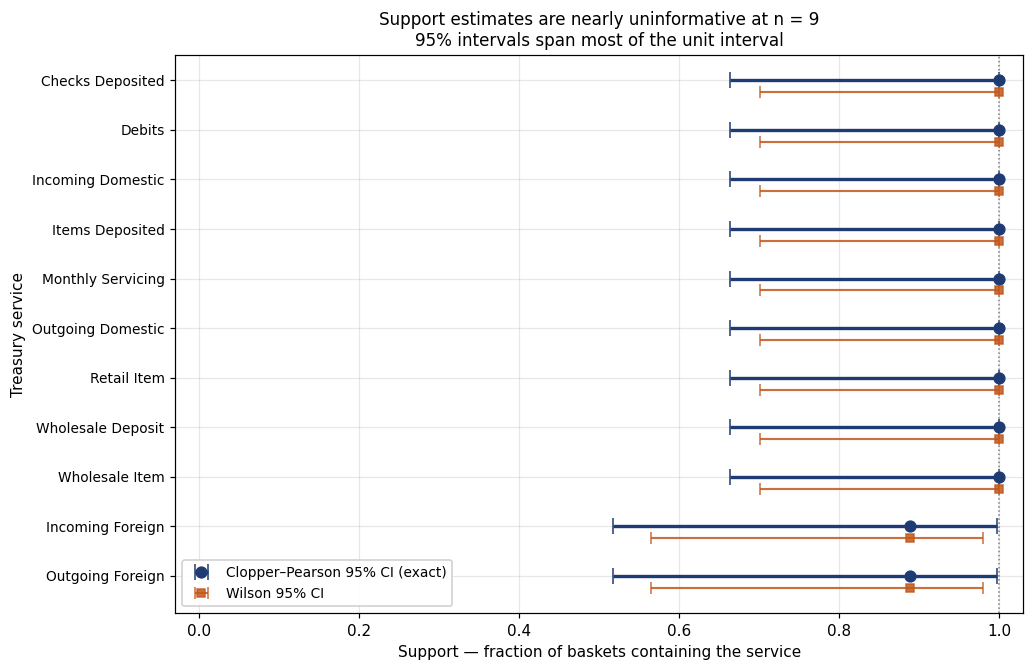

In [21]:
# --- Figure 1: support point estimates with exact CI error bars -----------
fig, ax = plt.subplots(figsize=(9.5, 6.2))
y = np.arange(len(ci))[::-1]

ax.errorbar(
    ci["support"], y,
    xerr=[(ci["support"] - ci["cp_lo"]).to_numpy(),
          (ci["cp_hi"] - ci["support"]).to_numpy()],
    fmt="o", color="#1f3b73", ecolor="#1f3b73", elinewidth=2.2, capsize=5,
    markersize=7, label="Clopper–Pearson 95% CI (exact)",
)
ax.errorbar(
    ci["support"], y - 0.24,
    xerr=[(ci["support"] - ci["wilson_lo"]).to_numpy(),
          (ci["wilson_hi"] - ci["support"]).to_numpy()],
    fmt="s", color="#c2571a", ecolor="#c2571a", elinewidth=1.4, capsize=4,
    markersize=5, alpha=0.85, label="Wilson 95% CI",
)

ax.set_yticks(y)
ax.set_yticklabels(ci["item"], fontsize=9)
ax.set_xlim(-0.03, 1.03)
ax.set_xlabel("Support — fraction of baskets containing the service")
ax.set_ylabel("Treasury service")
ax.set_title(
    f"Support estimates are nearly uninformative at n = {N_BASKETS}\n"
    "95% intervals span most of the unit interval", fontsize=11,
)
ax.axvline(1.0, color="grey", ls=":", lw=1)
ax.legend(loc="lower left", fontsize=9, framealpha=0.95)
fig.tight_layout()
plt.show()

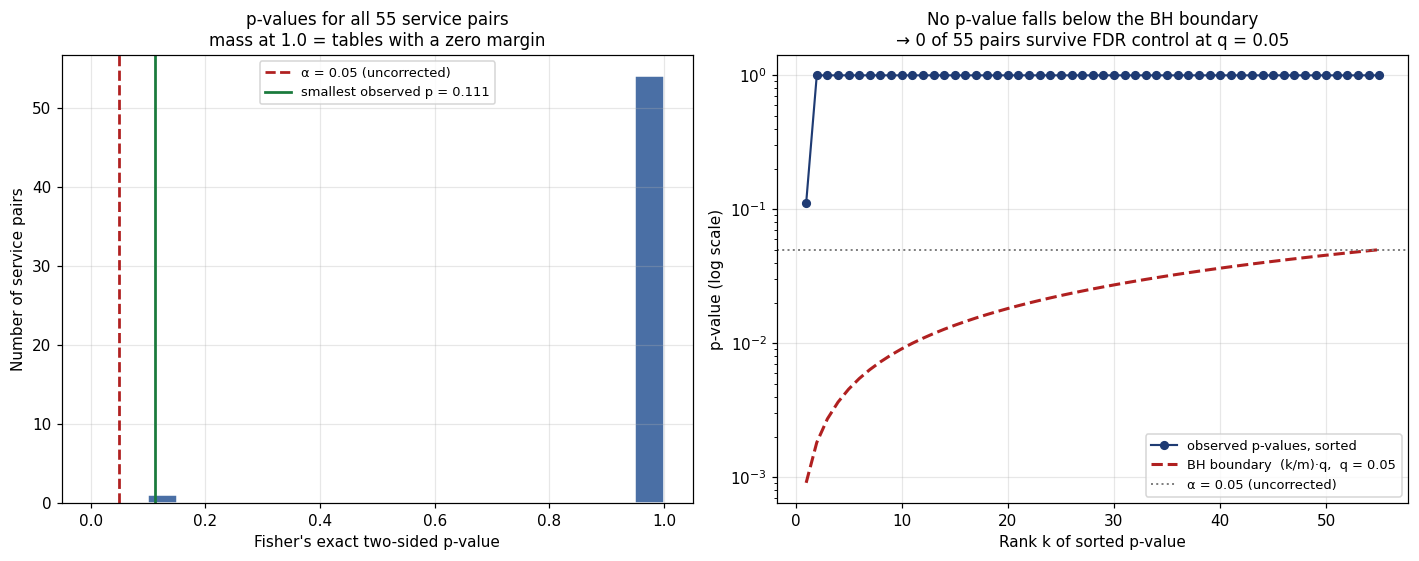

In [22]:
# --- Figure 2: p-value distribution vs the BH rejection boundary ---------
p_sorted = np.sort(tests["p_fisher"].fillna(1.0).to_numpy())
m = p_sorted.size
k = np.arange(1, m + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2))

ax1.hist(p_sorted, bins=np.linspace(0, 1, 21), color="#4a6fa5",
         edgecolor="white")
ax1.axvline(ALPHA, color="#b02020", ls="--", lw=1.8,
            label=f"α = {ALPHA} (uncorrected)")
ax1.axvline(p_sorted.min(), color="#1a7a3c", ls="-", lw=1.8,
            label=f"smallest observed p = {p_sorted.min():.3f}")
ax1.set_xlabel("Fisher's exact two-sided p-value")
ax1.set_ylabel("Number of service pairs")
ax1.set_title(f"p-values for all {m} service pairs\n"
              "mass at 1.0 = tables with a zero margin", fontsize=11)
ax1.legend(fontsize=8.5, loc="upper center")

ax2.plot(k, p_sorted, "o-", color="#1f3b73", ms=5, lw=1.4,
         label="observed p-values, sorted")
ax2.plot(k, (k / m) * FDR_Q, "--", color="#b02020", lw=2,
         label=f"BH boundary  (k/m)·q,  q = {FDR_Q}")
ax2.axhline(ALPHA, color="grey", ls=":", lw=1.3,
            label=f"α = {ALPHA} (uncorrected)")
ax2.set_xlabel("Rank k of sorted p-value")
ax2.set_ylabel("p-value (log scale)")
ax2.set_yscale("log")
ax2.set_title("No p-value falls below the BH boundary\n"
              f"→ 0 of {m} pairs survive FDR control at q = {FDR_Q}",
              fontsize=11)
ax2.legend(fontsize=8.5, loc="lower right")

fig.tight_layout()
plt.show()

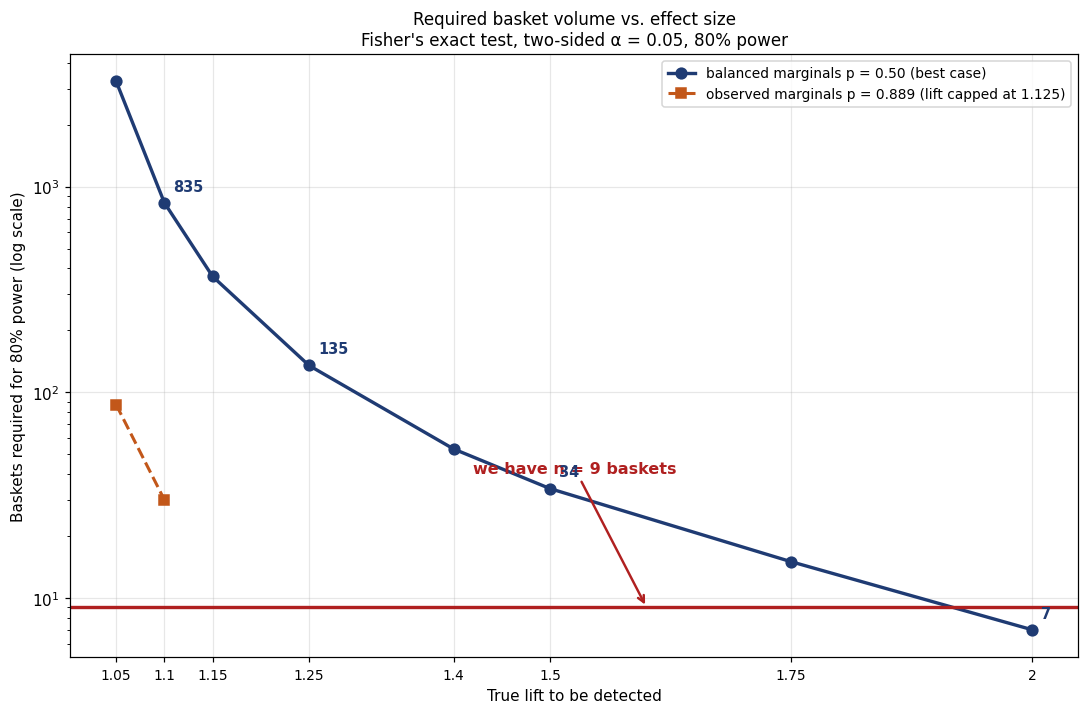

In [23]:
# --- Figure 3: required sample size vs true lift --------------------------
bal_all = sample_size[(sample_size["marginals"] == "balanced p=0.500")
                      & sample_size["feasible"]]
obs_all = sample_size[(sample_size["marginals"] == "observed p=0.889")
                      & sample_size["feasible"]]

fig, ax = plt.subplots(figsize=(10, 6.6))
ax.plot(bal_all["true_lift"], bal_all[POWER_COL], "o-", color="#1f3b73",
        lw=2.2, ms=7, label="balanced marginals p = 0.50 (best case)")
if len(obs_all):
    ax.plot(obs_all["true_lift"], obs_all[POWER_COL], "s--", color="#c2571a",
            lw=2, ms=7,
            label=f"observed marginals p = {OBSERVED_MARGIN:.3f} "
                  f"(lift capped at {max_feasible_lift(OBSERVED_MARGIN, OBSERVED_MARGIN):.3f})")

ax.axhline(N_BASKETS, color="#b02020", lw=2.2)
ax.annotate(
    f"we have n = {N_BASKETS} baskets",
    xy=(1.6, N_BASKETS), xytext=(1.42, N_BASKETS * 4.5),
    fontsize=10.5, color="#b02020", weight="bold",
    arrowprops=dict(arrowstyle="->", color="#b02020", lw=1.6),
)

for row in bal_all.itertuples(index=False):
    if row.true_lift in HEADLINE_LIFTS:
        need = getattr(row, POWER_COL)
        ax.annotate(f"{need:,.0f}", xy=(row.true_lift, need),
                    xytext=(6, 8), textcoords="offset points", fontsize=9.5,
                    color="#1f3b73", weight="bold")

ax.set_yscale("log")
ax.set_xlabel("True lift to be detected")
ax.set_ylabel(f"Baskets required for {int(TARGET_POWER * 100)}% power "
              f"(log scale)")
ax.set_title("Required basket volume vs. effect size\n"
             f"Fisher's exact test, two-sided α = {ALPHA}, "
             f"{int(TARGET_POWER * 100)}% power", fontsize=11)
ax.set_xticks(LIFT_GRID)
ax.set_xticklabels([f"{v:g}" for v in LIFT_GRID], fontsize=9)
ax.legend(fontsize=9, loc="upper right")
fig.tight_layout()
plt.show()

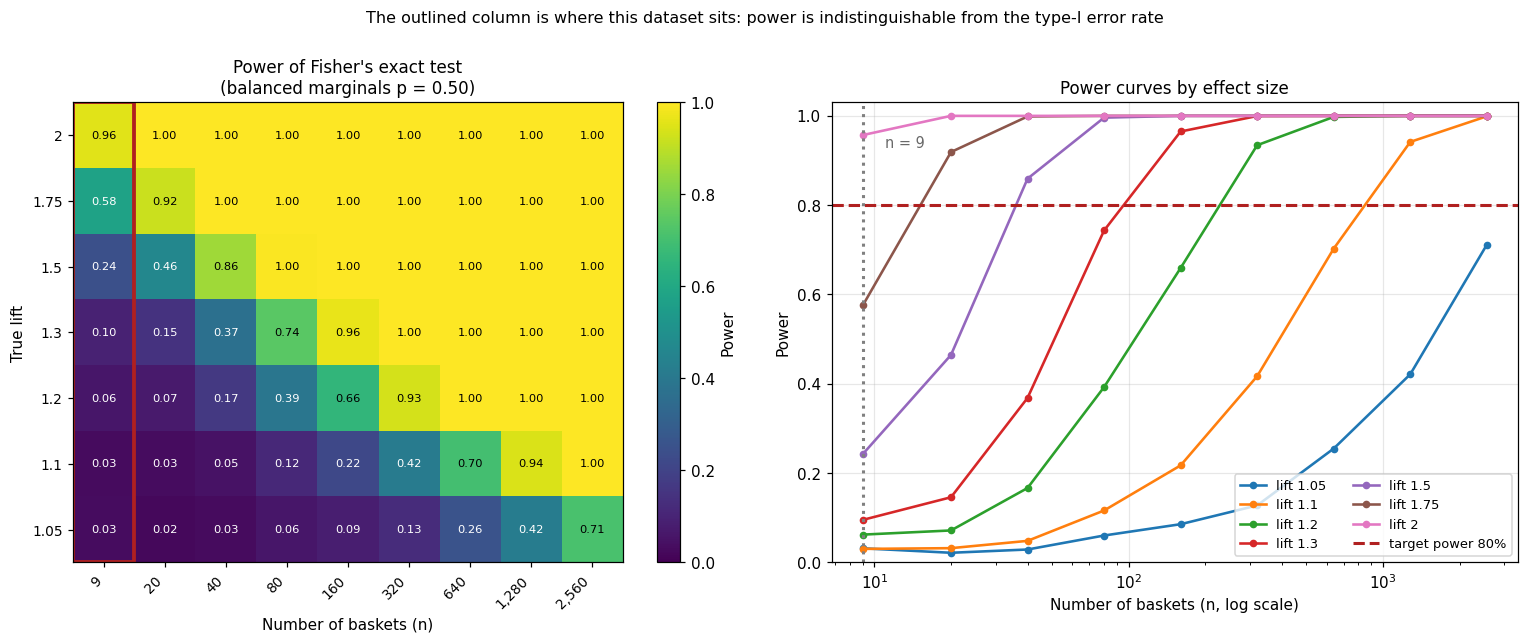

In [24]:
# --- Figure 4: power surface and curve family over (n, true lift) --------
n_axis = [9, 20, 40, 80, 160, 320, 640, 1280, 2560]
lift_axis = [1.05, 1.1, 1.2, 1.3, 1.5, 1.75, 2.0]

surface = np.full((len(lift_axis), len(n_axis)), np.nan)
for i, lift in enumerate(lift_axis):
    rng = np.random.default_rng(RNG_SEED + i)
    for j, n in enumerate(n_axis):
        surface[i, j] = simulate_power(n, lift, BALANCED_MARGIN,
                                       BALANCED_MARGIN, ALPHA,
                                       reps=POWER_REPS, rng=rng)

fig, (axh, axc) = plt.subplots(1, 2, figsize=(14, 5.8))

im = axh.imshow(surface, origin="lower", aspect="auto", cmap="viridis",
                vmin=0.0, vmax=1.0)
axh.set_xticks(range(len(n_axis)))
axh.set_xticklabels([f"{n:,}" for n in n_axis], rotation=45, ha="right",
                    fontsize=9)
axh.set_yticks(range(len(lift_axis)))
axh.set_yticklabels([f"{v:g}" for v in lift_axis], fontsize=9)
axh.set_xlabel("Number of baskets (n)")
axh.set_ylabel("True lift")
axh.set_title("Power of Fisher's exact test\n(balanced marginals p = 0.50)",
              fontsize=11)
axh.grid(False)
for i in range(len(lift_axis)):
    for j in range(len(n_axis)):
        axh.text(j, i, f"{surface[i, j]:.2f}", ha="center", va="center",
                 fontsize=7.5,
                 color="white" if surface[i, j] < 0.6 else "black")
axh.add_patch(plt.Rectangle((-0.5, -0.5), 1.0, len(lift_axis), fill=False,
                            edgecolor="#b02020", lw=2.5))
cb = fig.colorbar(im, ax=axh)
cb.set_label("Power")

for i, lift in enumerate(lift_axis):
    axc.plot(n_axis, surface[i], "o-", ms=4, lw=1.7, label=f"lift {lift:g}")
axc.axhline(TARGET_POWER, color="#b02020", ls="--", lw=2,
            label=f"target power {TARGET_POWER:.0%}")
axc.axvline(N_BASKETS, color="grey", ls=":", lw=2)
axc.annotate(f"n = {N_BASKETS}", xy=(N_BASKETS, 0.9), xytext=(11, 0.93),
             fontsize=9.5, color="dimgrey")
axc.set_xscale("log")
axc.set_xlabel("Number of baskets (n, log scale)")
axc.set_ylabel("Power")
axc.set_ylim(0.0, 1.03)
axc.set_title("Power curves by effect size", fontsize=11)
axc.legend(fontsize=8.5, loc="lower right", ncol=2)

fig.suptitle("The outlined column is where this dataset sits: "
             "power is indistinguishable from the type-I error rate",
             fontsize=10.5, y=1.00)
fig.tight_layout()
plt.show()

## 9. Conclusion and quantified recommendation

### Finding

**No association between any pair of treasury services is statistically
detectable in this snapshot.** Specifically:

- All 55 pairwise Fisher's exact tests fail to reject at α = 0.05 *before* any
  multiplicity correction. **Zero** pairs survive Benjamini–Hochberg at
  q = 0.05.
- 54 of the 55 tables have a zero margin, because 9 of the 11 services appear in
  every basket. A constant variable cannot be associated with anything; those
  p-values are 1.0 by construction, not by weak evidence.
- The single informative pair, `Incoming Foreign` × `Outgoing Foreign`, shows
  **perfect co-occurrence (8/8, Jaccard = 1.0)** — and its exact p-value is
  still **0.111**, because 1/C(9,8) = 1/9 is the smallest p-value those margins
  can produce. *Perfect association is not significant at n = 9.* No choice of
  algorithm, metric, or significance threshold changes that; the information is
  simply not present in 9 observations.
- χ², even Yates-corrected, is invalid here: the smallest expected cell count in
  these tables is far below the conventional threshold of 5. It is reported only
  to show the disagreement.
- 95% confidence intervals on support span a third or more of [0, 1]. Ranking
  services by adoption on this snapshot is not supportable.

### Reading the two marginal regimes together

Section 5 reports required sample sizes under two sets of marginals, and they
must be read together. Under *balanced* marginals (p = 0.5) a lift of 2.0 is
perfect association and is detectable at n ≈ 7 — so n = 9 is not by itself
fatal. What is fatal is n = 9 **combined with** the marginals this data
actually has: at p = 0.889 the largest lift that can exist is 1.125, and at
that ceiling the test has power ≈ 0.16 at n = 9, needing ≈ 30 baskets to reach
80%. Nine of eleven services being universal destroys the variance that a 2×2
test consumes. The constraint is therefore the *joint* shortage of baskets and
of adoption variation — and both are fixed by the same remedy: more
relationships.

**This is a data-volume problem, not an analytical one.** The sibling notebooks
are methodologically sound; they are being run on a sample that cannot support
inference. Their value is as reusable machinery, not as findings.

### Practical guidance

1. **Do not publish rule-mining output from this snapshot** as a business
   finding. Report it as a methodology artefact, with the non-significance
   stated on the same page as the metrics.
2. **Expand the basket population before re-running.** The binding constraint is
   the count of distinct `RELATIONSHIP_ID`, not the number of columns. Candidate
   levers: widen beyond `ACCOUNT_TYPE = 'Treasury - Cash Management'` (currently
   the only value present), pool across `DATE_PARTITION` snapshots to build a
   relationship-month panel, and consider lowering the basket grain to
   `CORE_ACCOUNT_ID` (97 rows) if accounts are a defensible basket unit.
3. **Expect marginals to improve with scale.** Nine of eleven services being
   universal is partly a small-sample artefact; a larger population will contain
   genuine non-adopters, which restores the variance these tests require. Until
   it does, the lift ceiling of 1.125 caps what is even representable.
4. **Re-run this notebook as a gate.** It is parameterised. Point it at a larger
   snapshot and it reports whether inference has become viable. Treat a
   non-empty BH-significant set as the entry criterion for any business
   narrative built on these rules.

The cell below prints the required basket volumes from the executed run, so the
recommendation is stated in numbers rather than prose.

In [25]:
bal = sample_size[(sample_size["marginals"] == "balanced p=0.500")
                  & sample_size["true_lift"].isin(HEADLINE_LIFTS)]

print("=" * 76)
print("QUANTIFIED RECOMMENDATION")
print("=" * 76)
print(f"Current basket count                      : {N_BASKETS}")
print(f"Items (services)                          : {matrix.shape[1]}")
print(f"Pairs tested                              : {len(tests)}")
print(f"Pairs significant, uncorrected alpha={ALPHA}  : "
      f"{int((tests['p_fisher'] < ALPHA).sum())}")
print(f"Pairs significant after BH q={FDR_Q}          : "
      f"{int(tests['significant_bh'].sum())}")
print(f"Smallest attainable p-value               : "
      f"{tests['p_fisher'].min():.4f}  (perfect 8/8 co-occurrence)")
print(f"Attainable lift values in this dataset    : "
      f"{report['distinct_lift_values']}")
print()
print(f"Baskets required for {int(TARGET_POWER * 100)}% power at two-sided "
      f"alpha={ALPHA}")
print("(balanced marginals -- a LOWER BOUND on the real requirement):")
print()
print(f"  {'true lift':>10} | {'baskets needed':>15} | {'x current n':>12} | "
      f"{'power at n=' + str(N_BASKETS):>14}")
print(f"  {'-' * 10} | {'-' * 15} | {'-' * 12} | {'-' * 14}")
for row in bal.itertuples(index=False):
    need = getattr(row, POWER_COL)
    print(f"  {row.true_lift:>10.2f} | {need:>15,.0f} | "
          f"{need / N_BASKETS:>11,.0f}x | {row.power_at_current_n:>14.3f}")

floor = bal[POWER_COL].min()
ceiling = bal[POWER_COL].max()
print()
print("BOTTOM LINE -- two constraints, one remedy:")
print(f"  1. Effect size. A subtle cross-sell signal (lift 1.10) needs "
      f"~{ceiling:,.0f} baskets;")
print(f"     a strong one (lift 1.50) needs ~{bal.loc[bal['true_lift'] == 1.5, POWER_COL].iloc[0]:,.0f}. "
      f"We have {N_BASKETS}.")
print(f"  2. Adoption variance. At the marginals this data actually has "
      f"(p={OBSERVED_MARGIN:.3f}),")
print(f"     the largest lift that can EXIST is "
      f"{max_feasible_lift(OBSERVED_MARGIN, OBSERVED_MARGIN):.3f}, and detecting even that")
print(f"     perfect co-occurrence needs "
      f"{obs.iloc[-1][POWER_COL]:,.0f} baskets. The lift-2.0 row below is")
print("     unattainable here precisely because 9 of 11 services are universal.")
print()
print(f"RECOMMENDATION: target a basket population on the order of "
      f"{ceiling:,.0f} distinct")
print("relationships, with genuine non-adopters present, before treating")
print("association-rule output from this data as evidence. At n=9 nothing is")
print("statistically detectable and no analytical choice changes that.")
print("=" * 76)


QUANTIFIED RECOMMENDATION
Current basket count                      : 9
Items (services)                          : 11
Pairs tested                              : 55
Pairs significant, uncorrected alpha=0.05  : 0
Pairs significant after BH q=0.05          : 0
Smallest attainable p-value               : 0.1111  (perfect 8/8 co-occurrence)
Attainable lift values in this dataset    : [1.0, 1.125]

Baskets required for 80% power at two-sided alpha=0.05
(balanced marginals -- a LOWER BOUND on the real requirement):

   true lift |  baskets needed |  x current n |   power at n=9
  ---------- | --------------- | ------------ | --------------
        1.10 |             835 |          93x |          0.036
        1.25 |             135 |          15x |          0.070
        1.50 |              34 |           4x |          0.227
        2.00 |               7 |           1x |          0.961

BOTTOM LINE -- two constraints, one remedy:
  1. Effect size. A subtle cross-sell signal (lift 1.10) nee